
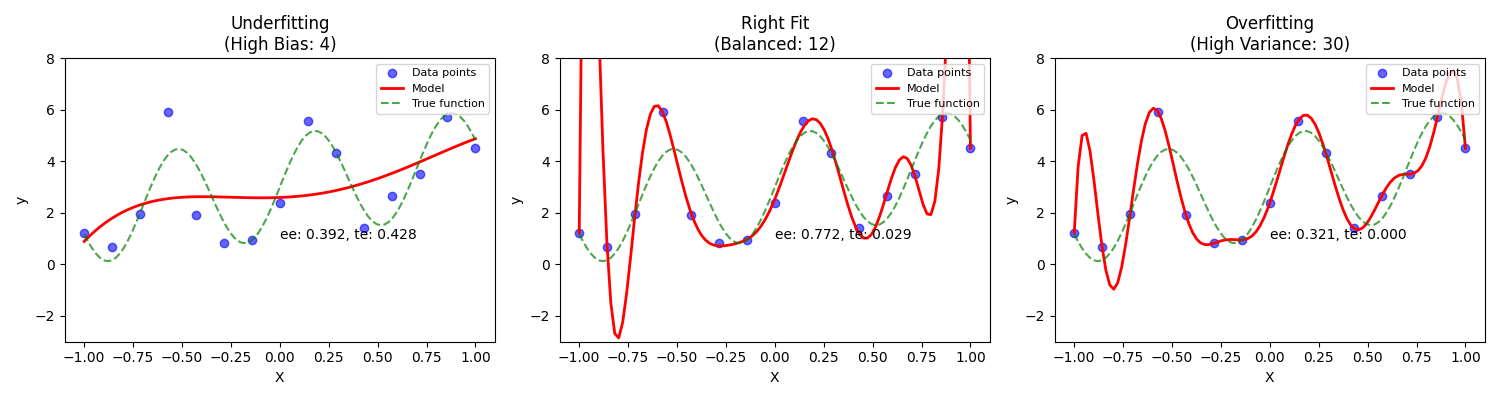

<Figure size 640x480 with 0 Axes>

In [1]:
import os
assert os.path.exists("ProbabilisticPerspective.ipynb"), \
    "ProbabilisticPerspective.ipynb should be in the same folder as this file"
%run -n ProbabilisticPerspective.ipynb

In [2]:
if __name__ == '__main__':
    X = np.linspace(0, 10, 30).reshape(-1, 1)
    y = truefun(X).ravel() + np.minimum(2, np.random.normal(0, 1.2, X.shape[0]))
    
    degree = 100
    
    model = make_pipeline(FourierFeatures(degree), LinearRegression())
    _, train_err = model.fit(X, y)
    train_errors = np.abs(y - model.predict(X))
    y_pred = model.predict(X_plot)
    y_true = truefun(X_plot).ravel()
    test_err = np.abs(y_pred - y_true)
    
    print(train_errors, test_err)

[0.00454906 0.10282506 0.41495412 0.9517476  1.06189079 0.27822223
 0.54957977 0.02140169 1.45166029 1.85711706 0.99744553 0.13378393
 0.09058704 0.6429552  1.01306993 0.43859125 0.09848429 0.68977981
 2.28246417 3.11331936 2.55937559 1.14908063 0.46941553 1.54987252
 3.10464452 3.25377526 1.99756331 0.77117234 0.15073539 0.02655461] [3.24846752e+03 2.93366844e+03 2.64583995e+03 2.38293707e+03
 2.14305322e+03 1.92440610e+03 1.72534267e+03 1.54431057e+03
 1.37987865e+03 1.23071920e+03 1.09557639e+03 9.73307842e+02
 8.62852944e+02 7.63213416e+02 6.73478992e+02 5.92803799e+02
 5.20410766e+02 4.55572751e+02 3.97621050e+02 3.45943645e+02
 2.99978008e+02 2.59195051e+02 2.23112543e+02 1.91281896e+02
 1.63297604e+02 1.38783478e+02 1.17382372e+02 9.87843120e+01
 8.26841978e+01 6.88141682e+01 5.69274348e+01 4.67869565e+01
 3.81924749e+01 3.09418843e+01 2.48726813e+01 1.98185636e+01
 1.56433444e+01 1.22084680e+01 9.40549765e+00 7.13997424e+00
 5.30495428e+00 3.83865602e+00 2.66296853e+00 1.723851

### Double Descent

Modern machine learnining avoids overfitting in overparameterized domains.

Degrees:  [  2   2   3   3   4   4   5   6   7   8  10  11  13  16  18  22  25  30
  35  41  48  56  66  77  90 106 124 146 171 200]


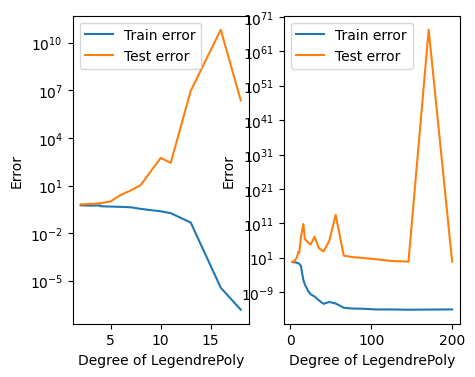

In [10]:

def truefun(X):
    return (2*X + np.cos(25*X))
    
if __name__ == '__main__':
    DEBUG = False
        
    if DEBUG: np.random.seed(43)
    low, high = -1, 1
    num_repetitions = 30
    num_data = 15
    
    X_plot = np.linspace(low, high, 1000).reshape(-1, 1)
    
    degrees = np.round(np.exp(np.linspace(np.log(2), np.log(200), 30))).astype(np.int64)
    print("Degrees: ", degrees)
    
    feature_name = ['LegendrePoly', 'PolynomialFeatures', 'FourierFeatures'][0]
    
    list_of_train_errors = []
    list_of_test_errors = []
    for degree in degrees:
        train_errors = []
        test_errors = []
        for _ in range(num_repetitions):
            X = np.random.uniform(low, high=high, size=(num_data, 1))
            y = truefun(X).ravel() + np.random.normal(0, 0.6, X.shape[0])
            
            feature_class = globals()[feature_name]
            model = make_pipeline(Normalizer(), feature_class(degree), LinearRegression())
            _, train_error = model.fit(X, y)
            y_pred = model.predict(X_plot)
            y_true = truefun(X_plot).ravel()
            test_error = model.error(y_pred, y_true)

            train_errors.append(train_error)
            test_errors.append(test_error)
        list_of_train_errors.append(sum(train_errors) / len(train_errors))
        list_of_test_errors.append(sum(test_errors) / len(test_errors))
    
    fig, axes = plt.subplots(1, 2, figsize=(5, 4))
    ax = axes[0]
    n = 15
    ax.set_xlabel(f'Degree of {feature_name}')
    ax.set_ylabel('Error')
    ax.set_yscale("log") 
    ax.plot(degrees[:n], list_of_train_errors[:n], label='Train error')
    ax.plot(degrees[:n], list_of_test_errors[:n], label='Test error')
    ax.legend()
    
    ax = axes[1]
    ax.set_xlabel(f'Degree of {feature_name}')
    #ax.set_xscale("log")
    ax.set_ylabel('Error')
    ax.set_yscale("log") 
    ax.plot(degrees, list_of_train_errors, label='Train error')
    ax.plot(degrees, list_of_test_errors, label='Test error')
    ax.legend()
